# El balance poblacional como esperanza del reemplazo de partículas, y las parcelas que pide el muestreo

**Pregunta:** ¿Es el producto de Whiten la esperanza de la regla de reemplazo de partículas que usan los modelos de elementos discretos de chancadores, y cuántas parcelas muestreadas necesita esa regla para reproducirlo con un error de un uno por ciento de la masa?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 02 de este tema
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook usted puede:

- decir qué hace la familia de reemplazo de partículas de los modelos de elementos discretos de chancadores, y qué parte de ella representa el balance poblacional;
- deducir en papel que la esperanza de la regla de reemplazo es el producto de Whiten, y explicar por qué una ejecución solo puede medir error de muestreo;
- ejecutar la caminata de reemplazo del pipeline con la selección y el quiebre propios del producto, y leer cómo se reduce su error al crecer el número de parcelas;
- decir con claridad qué puede afirmar esta comparación sobre los modelos de elementos discretos y qué no.

## Preparación

Numpy y matplotlib. Los sorteos aleatorios salen del generador de numpy con una semilla fija, de modo que cada ejecución da los mismos números.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son las piezas del notebook 02 y las dos funciones del pipeline que hacen posible este notebook: `assemble_chamber`, que arma la selección y el quiebre de un punto de operación como lo hace el motor, y `replacement_walk`, la regla de reemplazo de partículas misma. Ambas viven en `data-pipeline/pipeline/model/crusher/whiten.py` junto al solucionador de Whiten, así que el notebook no define ningún método propio.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher.whiten import assemble_chamber, replacement_walk, whiten_solve
from pipeline.model.crusher import Operating, evaluate, grid_edges, grid_mid
from pipeline.model.crusher.linalg import solve_lu
from pipeline.model.crusher.sieve import size_at_passing, to_psd
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

El caso de referencia S01. En este repositorio no hay código ni datos de elementos discretos versionados, y el SDD declara la simulación de elementos discretos como no incluida en este lanzamiento, de modo que la literatura que sigue se cita y no se ejecuta. Propietario: este repositorio, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Clase de licencia: MIT; los artefactos versionados los escribe el pipeline a partir de los parámetros de cada caso. Archivo leído: `data/derived/manifests/S01.json`, bloque `params`.

La celda lee S01 y ejecuta el motor una vez para obtener la distribución de alimentación en la malla.

In [2]:
# Lea S01, ejecute el motor una vez para su alimentación y fije la malla
manifest = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))
op = Operating(**manifest["params"])
result = evaluate(op)
edges, mids = grid_edges(), np.array(grid_mid())
K = len(mids)
feed = np.array(result.feed.mass)

print("clases:", K, "| masa de alimentación:", feed.sum().round(12), "| P80 del motor:", round(result.p80, 3), "mm")

clases: 28 | masa de alimentación: 1.0 | P80 del motor: 27.698 mm


## Método

**Paso 1, de dónde viene la regla.** El estado del arte para el mecanismo de un chancador es el método de elementos discretos, que resuelve las partículas, sus contactos y su quiebre en la geometría de la cámara. Hay dos familias en las fuentes que cita el producto. En el **reemplazo de partículas**, una partícula que cumple un criterio de quiebre se elimina y se reemplaza por un conjunto de fragmentos más pequeños con tamaños tomados de una función de quiebre; Cleary y Sinnott (2015; https://doi.org/10.1016/j.mineng.2014.10.021) la desarrollan para chancadores de compresión. En la familia de **partículas ligadas** la roca es un conjunto de subpartículas y la fractura emerge del modelo de enlace; Quist y Evertsson (2016; https://doi.org/10.1016/j.mineng.2015.11.004) la calibran con quiebre de partículas individuales para un chancador de cono. Ambas son herramientas fuera de línea: un paso industrial toma horas de cálculo, por eso el balance poblacional es la aproximación rápida que el estudio ejecuta en vivo.

Hay que decir con exactitud qué se puede ejecutar aquí y qué no. El código y los datos de ninguna de las dos familias están en este repositorio, así que ninguno de sus números se reproduce, y por eso el tema no tiene un notebook de nivel 3. Lo que la familia de reemplazo comparte con el balance es una lectura estocástica de las mismas dos funciones: una partícula seleccionada se reemplaza por fragmentos sorteados de la distribución de aparición, y un fragmento que todavía es seleccionado se quiebra otra vez. Esa regla puede ejecutarse con la selección $C$ y el quiebre $B$ propios del producto, con cada unidad de masa como una parcela para que la caminata siga siendo lineal en la masa.

**Paso 2, la esperanza en papel.** Sea $f$ la distribución de alimentación sobre las clases y sea $n_k$ la parte esperada de la alimentación que está dentro de la cámara en la pasada $k$, de modo que $n_0 = f$. En cada pasada una parcela de la clase $j$ es atrapada con probabilidad $c_j$ y reemplazada por una parcela de la clase $i$ con probabilidad $B_{ij}$; las parcelas que no son atrapadas salen como producto. En esperanza, $n_{k+1} = B\,C\,n_k$ y el producto recoge $(I - C)\,n_k$ en cada pasada, así que

$$\mathbb{E}[p] = (I - C)\sum_{k \ge 0} (B C)^k f = (I - C)(I - B C)^{-1} f$$

que es el producto de Whiten del notebook 02 (Whiten, 1972; https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf; Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193). La serie es finita, porque $BC$ es estrictamente triangular inferior y cada reemplazo cae en una clase más fina. La consecuencia es el punto de este notebook: la coincidencia entre la caminata y el balance es una identidad, no un hallazgo. Una ejecución no puede probar si la regla de reemplazo describe un chancador; solo puede medir qué tan grande es el error de muestreo de una caminata de $N$ parcelas, y esa es la pregunta práctica, porque la caminata es el sustituto barato de una simulación que cuesta horas.

**Paso 3, el modelo.** La celda pide a `assemble_chamber` el vector de selección $c$ y la matriz de quiebre $B$ de S01, resuelve el balance con el solucionador de Whiten del motor y lee el producto de referencia. Imprime los tamaños que se seleccionan por azar, las clases que siempre y que nunca son atrapadas, el P80 del producto y la parte de la masa sobre el borde de clase de 20 mm, los dos números que la caminata debe reproducir.

In [3]:
# Pida al pipeline c y B de S01, resuelva el balance y lea el producto de referencia
c, B = assemble_chamber(op)
reference = np.array(whiten_solve(c.tolist(), B.ravel().tolist(), feed.tolist(), K).product)
by_chance = mids[(c > 0) & (c < 1)]
coarse = [i for i in range(K) if edges[i + 1] >= 19.9]
balance_p80 = size_at_passing(to_psd(edges, reference.tolist()), 0.8)
print("tamaños medios de clase seleccionados con probabilidad entre 0 y 1 [mm]:", np.round(by_chance, 1))
coarse_share = float(reference[coarse].sum())
print("siempre atrapadas (C = 1):", int((c == 1).sum()), "| nunca atrapadas (C = 0):", int((c == 0).sum()))
print("P80 del balance [mm]:", round(balance_p80, 3), "| masa sobre el borde de 20 mm:", round(coarse_share, 4))

tamaños medios de clase seleccionados con probabilidad entre 0 y 1 [mm]: [53.8 38.1]
siempre atrapadas (C = 1): 4 | nunca atrapadas (C = 0): 22
P80 del balance [mm]: 27.698 | masa sobre el borde de 20 mm: 0.2965


**Paso 4, la caminata de reemplazo.** `replacement_walk` sortea las parcelas de alimentación de la distribución de alimentación, y luego repite una sola regla hasta que no queda ninguna parcela en la cámara: cada parcela de la clase $j$ es atrapada con probabilidad $c_j$, y una parcela atrapada se reemplaza por una parcela de la clase $i$ sorteada con probabilidad $B_{ij}$; una parcela que no es atrapada sale y se cuenta en el producto. El ciclo trabaja con conteos de parcelas por clase, así que cada pasada es un sorteo binomial por clase y un sorteo multinomial por clase atrapada, y termina porque cada reemplazo cae estrictamente en una clase más fina. Tiene semilla y entrega el producto como distribución junto con el número medio de apriete que sufrió una parcela. La celda ejecuta una caminata de 200 000 parcelas e imprime a qué distancia queda del balance.

In [4]:
# Una caminata de 200 000 parcelas, con semilla, frente al balance
walk, nips_per_parcel = replacement_walk(c, B, feed, 200_000, 42)
print("mayor diferencia de masa por clase con el producto de Whiten:", np.abs(walk - reference).max().round(5))
print("distancia de variación total:", (0.5 * np.abs(walk - reference).sum()).round(5))

mayor diferencia de masa por clase con el producto de Whiten: 0.00168
distancia de variación total: 0.00372


La caminata con 200 000 parcelas queda a menos de 0,17 puntos porcentuales del balance en cada clase. La figura superpone los dos productos clase por clase. Ambos son cero en las clases gruesas que siempre son atrapadas, y ambos ponen el grueso de su masa entre 5 y 40 mm.

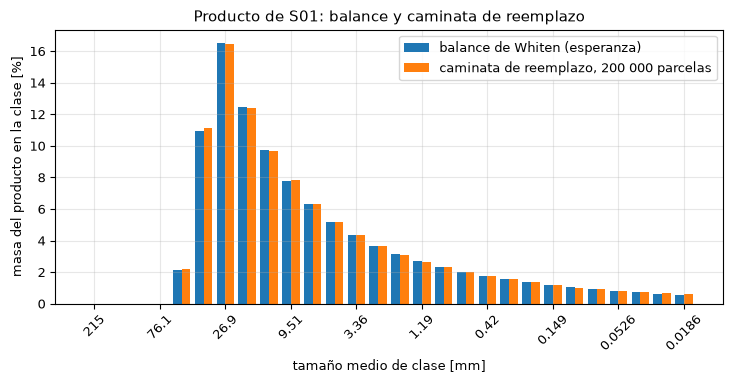

In [5]:
# Gráfico de barras del producto de Whiten y del producto de la caminata de reemplazo por clase
position = np.arange(K)
fig, ax = plt.subplots()
ax.bar(position - 0.2, reference * 100, 0.4, label="balance de Whiten (esperanza)")
ax.bar(position + 0.2, walk * 100, 0.4, label="caminata de reemplazo, 200 000 parcelas")
ax.set_xticks(position[::3], [f"{m:.3g}" for m in mids[::3]], rotation=45)
ax.set_xlabel("tamaño medio de clase [mm]")
ax.set_ylabel("masa del producto en la clase [%]")
ax.set_title("Producto de S01: balance y caminata de reemplazo")
ax.legend()
fig.tight_layout()
plt.show()

Las barras coinciden a la vista en cada clase, como dice el álgebra del Paso 2 que deben: el balance es la esperanza de la caminata, y la caminata es un muestreo del balance. La imagen no puede mostrar la calidad de la coincidencia, porque una diferencia de 0,17 puntos queda bajo la resolución de las barras, y no puede mostrar que la regla sea correcta para un chancador real, porque ambas barras usan las mismas $C$ y $B$. Lo que sí muestra es que la caminata pone su masa donde la pone el balance, con las mismas clases gruesas vacías y el mismo grueso entre 5 y 40 mm.

**Paso 5, un segundo observable, la recirculación.** El producto es una salida de la caminata; el número de eventos de apriete es otra, y el balance también la predice: es la suma de $c_j x_j$ sobre las clases, la cantidad que el notebook 02 leyó como 0,8858 apriete por unidad de alimentación. La celda resuelve el balance con la rutina LU del motor para esa suma y la compara con el número de apriete por parcela que contó la caminata.

In [6]:
# Eventos de apriete por unidad de alimentación del balance (solución LU del motor) frente a la cuenta de la caminata
x = np.array(solve_lu((np.eye(K) - B * c[None, :]).ravel().tolist(), feed.tolist(), K))
balance_nips, walk_nips = float((c * x).sum()), float(nips_per_parcel)
print("balance, suma de c x:", round(balance_nips, 4), "| caminata, apriete por parcela:", round(walk_nips, 4))

balance, suma de c x: 0.8858 | caminata, apriete por parcela: 0.8843


La caminata cuenta 0,8843 apriete por parcela frente a los 0,8858 del balance, una diferencia de 0,0015 que es otra vez error de muestreo, y confirma la lectura del notebook 02: las parcelas pasan por el apriete cerca de 0,9 veces en promedio, así que la recirculación es real también en la caminata muestreada. El paso siguiente mide cómo se reduce ese error con el número de parcelas.

**Paso 6, el error de muestreo frente al número de parcelas.** La celda ejecuta la caminata con $10^3$, $10^4$, $10^5$ y $10^6$ parcelas, cinco semillas independientes cada una, e imprime la distancia de variación total media, la menor y la mayor al balance, la mitad de la suma de las diferencias absolutas por clase, que es la parte de la masa que cae en una clase equivocada.

In [7]:
# Distancia de variación total de la caminata al producto de Whiten frente al número de parcelas, 5 semillas
sizes = [10 ** 3, 10 ** 4, 10 ** 5, 10 ** 6]
distance = {}
for n_parcels in sizes:
    distance[n_parcels] = []
    for seed in range(5):
        sampled = replacement_walk(c, B, feed, n_parcels, seed)[0]
        distance[n_parcels].append(0.5 * np.abs(sampled - reference).sum())
for n_parcels, values in distance.items():
    print(f"{n_parcels:>9,d} parcelas: media {np.mean(values):.5f}, mín {np.min(values):.5f}, máx {np.max(values):.5f}")

    1,000 parcelas: media 0.05660, mín 0.03841, máx 0.07280
   10,000 parcelas: media 0.01649, mín 0.01410, máx 0.01867
  100,000 parcelas: media 0.00597, mín 0.00396, máx 0.00719
1,000,000 parcelas: media 0.00160, mín 0.00136, máx 0.00193


La figura grafica la distancia media en ejes logarítmicos frente a la ley de uno sobre raíz cuadrada trazada por el primer punto.

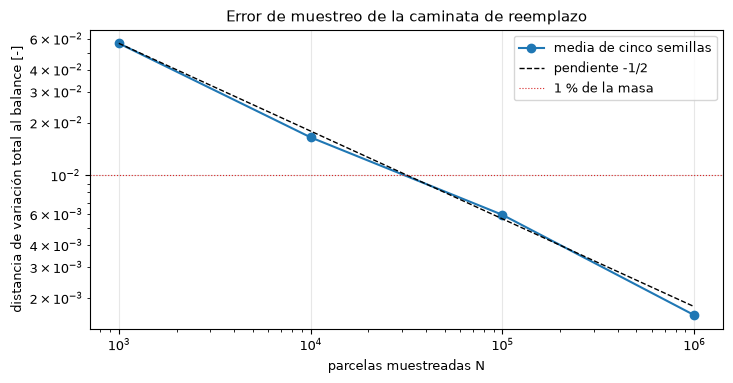

pendiente ajustada: -0.509


In [8]:
# Grafique la distancia media en ejes logarítmicos con la ley 1 / sqrt(N) por el primer punto
mean_distance = np.array([np.mean(distance[s]) for s in sizes])
fig, ax = plt.subplots()
ax.loglog(sizes, mean_distance, "o-", label="media de cinco semillas")
ax.loglog(sizes, mean_distance[0] * np.sqrt(sizes[0] / np.array(sizes)), "k--", lw=1, label="pendiente -1/2")
ax.axhline(0.01, color="tab:red", lw=0.8, ls=":", label="1 % de la masa")
ax.set_xlabel("parcelas muestreadas N")
ax.set_ylabel("distancia de variación total al balance [-]")
ax.set_title("Error de muestreo de la caminata de reemplazo")
ax.legend()
fig.tight_layout()
plt.show()
slope = np.polyfit(np.log(sizes), np.log(mean_distance), 1)[0]
print("pendiente ajustada:", round(float(slope), 3))

La distancia medida baja con una pendiente cercana a $-1/2$, la ley del muestreo de Monte Carlo, y cruza la línea de 1 por ciento entre $10^4$ y $10^5$ parcelas. La caminata converge entonces al balance a la tasa estándar, y no hay sesgo que encontrar a esta resolución, como exige la esperanza del Paso 2. La figura no dice que el balance sea correcto para un chancador real. Dice que el balance es lo que da la regla de reemplazo cuando se alimenta con las mismas $C$ y $B$, de modo que toda la diferencia entre una simulación de reemplazo de partículas y este producto está en el origen de $C$ y $B$: la DEM las deriva de la mecánica de contacto y de la geometría de la cámara, el producto de las relaciones publicadas y una calibración.

**Paso 7, otras aberturas y otros minerales.** Un punto de operación podría ser una coincidencia de los números. La celda repite la comparación con tres aberturas de lado cerrado y tres durezas de mineral, nueve combinaciones, cada una con su propio vector de selección y matriz de quiebre de `assemble_chamber`, 100 000 parcelas y una semilla, e imprime la distancia de variación total de la caminata al balance para cada una, junto con la mayor brecha relativa en el P80 del producto.

In [9]:
# Distancia de variación total de la caminata al balance con tres aberturas y tres durezas de mineral
print("CSS [mm]   A*b = 30    A*b = 55    A*b = 110")
worst_distance, p80_gap = 0.0, 0.0
for css in (op.css_mm * 0.7, op.css_mm, op.css_mm * 1.3):
    row = []
    for axb in (30, 55, 110):
        cc, BB = assemble_chamber(replace(op, css_mm=css, ore_axb=axb))
        ref = np.array(whiten_solve(cc.tolist(), BB.ravel().tolist(), feed.tolist(), K).product)
        product_walk = replacement_walk(cc, BB, feed, 100_000, 7)[0]
        row.append(0.5 * np.abs(product_walk - ref).sum())
        p80_walk = size_at_passing(to_psd(edges, product_walk.tolist()), 0.8)
        p80_gap = max(p80_gap, abs(p80_walk / size_at_passing(to_psd(edges, ref.tolist()), 0.8) - 1))
    worst_distance = max(worst_distance, *row)
    print(f"{css:7.1f}  " + "  ".join(f"{v:10.5f}" for v in row))
print("la peor de las nueve:", round(worst_distance, 5), "| mayor brecha relativa de P80:", f"{p80_gap * 100:.3f} %")

CSS [mm]   A*b = 30    A*b = 55    A*b = 110
   22.4     0.00685     0.00567     0.00523
   32.0     0.00542     0.00478     0.00351
   41.6     0.00519     0.00540     0.00482
la peor de las nueve: 0.00685 | mayor brecha relativa de P80: 0.295 %


Las nueve distancias son del mismo tamaño pequeño, unas milésimas, así que la coincidencia es una propiedad de la regla y no de los números de S01, justo como dice el álgebra. El mineral más duro con la abertura más cerrada necesita la mayor recirculación y da la mayor distancia de la tabla, porque tiene las caminatas más largas. La última celda traduce la distancia al número que le importa a una planta, el P80 del producto, leído con la misma interpolación del motor, y lo compara con el valor propio del motor en cinco semillas.

In [10]:
# P80 del producto de la caminata con la interpolación del motor, frente al P80 del motor
walk_p80 = []
for seed in range(5):
    product = replacement_walk(c, B, feed, 100_000, seed)[0]
    walk_p80.append(size_at_passing(to_psd(edges, product.tolist()), 0.8))
worst_gap = max(abs(v - result.p80) for v in walk_p80) / result.p80 * 100
print("P80 de la caminata en cinco semillas [mm]:", np.round(walk_p80, 3))
print("P80 del motor [mm]:", round(result.p80, 3), "| mayor diferencia relativa:", f"{worst_gap:.3f} %")

P80 de la caminata en cinco semillas [mm]: [27.811 27.617 27.795 27.704 27.686]
P80 del motor [mm]: 27.698 | mayor diferencia relativa: 0.409 %


El P80 de cinco caminatas independientes de 100 000 parcelas se dispersa alrededor del valor del motor en unas décimas de punto porcentual, la escala que una planta nunca notaría y la escala en que la caminata deja de valer su costo adicional. Los cinco valores no se desplazan hacia un solo lado del valor del motor, que es como se ve un muestreador sin sesgo. Este es el uso práctico de la caminata: pone precio, en parcelas, al error de muestreo de una simulación de tipo reemplazo, frente a un balance que cuesta un milisegundo.

## Resultados

**Respuesta:** sí, y por construcción. La esperanza de la regla de reemplazo es el producto de Whiten (Paso 2), así que lo que miden las ejecuciones es el error de muestreo. Con 200 000 parcelas la mayor diferencia de masa por clase con el balance es 0,00168 y la distancia de variación total 0,00372, y la caminata cuenta 0,8843 eventos de apriete por parcela frente a los 0,8858 del balance. La distancia baja con una pendiente ajustada de -0,509 al crecer el número de parcelas, desde una media de 0,01649 con 10 000 parcelas hasta 0,00597 con 100 000, de modo que cruza 1 por ciento de la masa entre ambas. En nueve combinaciones de abertura y mineral la peor distancia es 0,00685 y la peor brecha de P80 0,295 por ciento, y el P80 de cinco caminatas de 100 000 parcelas queda a menos de 0,409 por ciento de los 27,698 mm del motor. Un presupuesto de 100 000 parcelas da entonces el producto con un error de unas décimas de punto porcentual de la masa.

La primera figura muestra el producto clase por clase, la segunda la ley de convergencia. Un validador concluiría que el modelo rápido del producto y la regla de reemplazo de la familia de elementos discretos comparten su álgebra, y que el error de muestreo de la regla es controlado y estándar. Los límites honestos son tres. La caminata no reproduce ningún número de Cleary y Sinnott (2015) ni de Quist y Evertsson (2016): no hay código ni datos de ellos aquí, y la simulación de elementos discretos no es un método de este lanzamiento. No tiene geometría, ni mecánica de contacto, ni desgaste, ni formas de partícula, que es lo que una simulación de elementos discretos compra con sus horas de cálculo. Y la coincidencia es de la regla, no de las constantes: si $C$ y $B$ describen un chancador dado se resuelve frente a mediciones, en los temas 05 y 06.

## Resumen

El balance poblacional es la esperanza exacta de la regla de reemplazo de partículas, la caminata es su muestreo de Monte Carlo, y su brecha se reduce como el inverso de la raíz cuadrada del número de parcelas. Lo que agrega el estado del arte de elementos discretos es la física que produce $C$ y $B$, no un álgebra distinta, y esa física no está en este lanzamiento. El estudio conserva la forma barata, para que un lector mueva un control y vea un producto en un milisegundo, y es explícito en que sus $C$ y $B$ están calibradas, no derivadas. El tema 04 toma el lado de la potencia del modelo: capacidad, abertura y energía.

## Referencias

- Cleary, P. W., Sinnott, M. D. (2015), Simulation of particle flows and breakage in crushers using DEM: Part 1 - Compression crushers, Minerals Engineering 74, 178-197. https://doi.org/10.1016/j.mineng.2014.10.021
- Quist, J., Evertsson, C. M. (2016), Cone crusher modelling and simulation using DEM, Minerals Engineering 85, 92-105. https://doi.org/10.1016/j.mineng.2015.11.004
- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193